<a href="https://colab.research.google.com/github/tpeoples1911/Data-Science-Research-Assignments/blob/main/MIS769_HW2_MapReduce_Spark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Homework 2: MapReduce Concepts & Spark Fundamentals
**MIS 769 - Big Data Analytics for Business | Spring 2026**

**Points:** 20 | **Due:** See WebCampus for deadline

**Author:** Richard Young, Ph.D. | UNLV Lee Business School

**Compute:** CPU (free tier)

---

## What You'll Learn

1. Set up Apache Spark on Google Colab
2. Understand how Spark partitions data for parallel processing
3. **Measure and compare** processing performance with different configurations
4. Apply K-Means clustering and interpret business results
5. **Draw your own diagram** explaining distributed computing

---

## The Big Picture

When data gets too big for one computer, we split the work across many computers. **Spark** is the industry-standard tool for this.

```
YOUR LAPTOP                           SPARK CLUSTER
+----------------------+            +---------------------------+
|                      |            |     Driver Program        |
|   1 million rows     |            |         +----+            |
|   Takes: 10 minutes  |   ------>  |         |    |            |
|                      |            |    +----+----+----+       |
+----------------------+            |    |    |    |    |       |
                                    |   W1   W2   W3   W4       |
                                    |  250K 250K 250K 250K      |
                                    |  each worker in parallel  |
                                    +---------------------------+
```

## MapReduce & Spark Architecture

The diagram below shows how **MapReduce** breaks problems into parallel tasks, and how **Spark** improves on this with in-memory processing.

mapreduce_spark.svg

## K-Means Clustering Visualization

The diagram below illustrates how **K-Means clustering** works - the unsupervised learning algorithm you'll implement in Part 4.

kmeans_clustering.svg

**Key Concepts:**
1. **Initialize** k cluster centers (centroids) randomly
2. **Assign** each data point to its nearest centroid
3. **Update** centroids to the mean of assigned points  
4. **Repeat** until convergence (centroids stop moving)

In Part 4, you'll apply K-Means to group streaming content by features like release year and description length.

---

---

## Part 1: Spark Environment Setup (3 points)

Let's install and configure Apache Spark on Google Colab.

In [21]:
# Step 1: Install Java, PySpark, and findspark
# Run this cell and WAIT for it to complete before proceeding

import os
import subprocess

# Install Java 11
print("📦 Installing Java 11...")
os.system("apt-get update -qq && apt-get install -y -qq openjdk-11-jdk-headless > /dev/null 2>&1")

# Set JAVA_HOME
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["PATH"] = f"{os.environ['JAVA_HOME']}/bin:" + os.environ["PATH"]

# Verify Java
java_check = subprocess.run(["java", "-version"], capture_output=True, text=True)
print(f"✅ Java installed: {java_check.stderr.split(chr(10))[0]}")

# Install PySpark and findspark (specific versions for compatibility)
print("📦 Installing PySpark...")
os.system("pip install -q pyspark==3.5.0 findspark")

# Initialize findspark
import findspark
findspark.init()

print("✅ Setup complete! You can now run the next cell.")

📦 Installing Java 11...
✅ Java installed: openjdk version "11.0.32" 2026-07-21
📦 Installing PySpark...
✅ Setup complete! You can now run the next cell.


In [22]:
# Step 2: Create a Spark Session
# Make sure Step 1 completed successfully first!

from pyspark.sql import SparkSession
import time

spark = (
    SparkSession.builder
    .appName("MIS769_HW2")
    .master("local[2]")  # Use 2 CPU cores
    .config("spark.driver.memory", "2g")
    .config("spark.ui.showConsoleProgress", "false")  # Cleaner output
    .getOrCreate()
)

print("✅ Spark Session Created!")
print(f"   App Name: {spark.sparkContext.appName}")
print(f"   Master: {spark.sparkContext.master}")
print(f"   Default Parallelism: {spark.sparkContext.defaultParallelism}")

✅ Spark Session Created!
   App Name: MIS769_HW2
   Master: local[2]
   Default Parallelism: 2


**Question 1:** What does `local[2]` mean? What would `local[4]` do differently?

*Your answer here:*
**Here with local 2, it is telling the session to run locally on my machine and 2 tasks at a time. With the changes going to local 4, it would run considerably faster and run 4 tasks at a time.**

---

## Part 2: Understanding Data Partitioning (5 points)

### 2.1 Create Sample Data and Partition It

In [23]:
import random

# Create sample data: 100,000 random numbers
data_list = [random.randint(1, 1000) for _ in range(100000)]
print(f"Created {len(data_list):,} data points")

# Create RDD with 4 partitions
rdd = spark.sparkContext.parallelize(data_list, 4)
print(f"Number of partitions: {rdd.getNumPartitions()}")

Created 100,000 data points
Number of partitions: 4


In [24]:
# Visualize how data is distributed across partitions
def count_partition(index, iterator):
    count = sum(1 for _ in iterator)
    yield (index, count)

partition_counts = rdd.mapPartitionsWithIndex(count_partition).collect()

print("\n📊 DATA DISTRIBUTION ACROSS PARTITIONS")
print("-" * 40)
for partition_id, count in partition_counts:
    bar = "█" * (count // 1000)
    print(f"Partition {partition_id}: {count:,} items {bar}")


📊 DATA DISTRIBUTION ACROSS PARTITIONS
----------------------------------------
Partition 0: 24,576 items ████████████████████████
Partition 1: 25,600 items █████████████████████████
Partition 2: 24,576 items ████████████████████████
Partition 3: 25,248 items █████████████████████████


### 2.2 The MapReduce Pattern

Let's see MapReduce in action: count how many times each number appears.

In [25]:
# MapReduce: Count frequency of each number
# MAP: Transform each number to (number, 1)
# REDUCE: Sum up all the 1s for each number

start_time = time.time()

# The MapReduce pattern
frequency = (
    rdd
    .map(lambda x: (x, 1))           # MAP: (number, 1)
    .reduceByKey(lambda a, b: a + b)  # REDUCE: sum counts
)

# Get top 10 most frequent numbers
top_10 = frequency.takeOrdered(10, key=lambda x: -x[1])

elapsed = time.time() - start_time

print("📊 TOP 10 MOST FREQUENT NUMBERS")
print("-" * 30)
for num, count in top_10:
    print(f"   Number {num:4d}: {count:4d} times")
print(f"\n⏱️ Time taken: {elapsed:.3f} seconds")

📊 TOP 10 MOST FREQUENT NUMBERS
------------------------------
   Number  427:  129 times
   Number  293:  126 times
   Number  130:  126 times
   Number  153:  125 times
   Number  728:  124 times
   Number  444:  124 times
   Number  944:  124 times
   Number  332:  124 times
   Number  855:  123 times
   Number  695:  123 times

⏱️ Time taken: 1.124 seconds


### 💡 Try It Yourself: Search for Your Favorite Number

How would you search for a specific number? For example, if you want to find how many times the number **103** appears, you could filter the frequency RDD:

```python
# Find count for a specific number
my_number = 103
result = frequency.filter(lambda x: x[0] == my_number).collect()
if result:
    print(f"Number {my_number} appears {result[0][1]} times")
else:
    print(f"Number {my_number} not found")
```

**Try it:** Change `my_number` to your favorite number and run the code above!

In [ ]:
# Try it! Search for your favorite number
my_number = 50  # <-- Change this to any number between 1-1000

result = frequency.filter(lambda x: x[0] == my_number).collect()
if result:
    print(f"🔍 Number {my_number} appears {result[0][1]} times")
else:
    print(f"🔍 Number {my_number} not found in the dataset")

---

## Part 3: Performance Experiment (5 points)

Let's measure how the number of cores affects processing speed.

In [ ]:
# Function to run our MapReduce with different core counts
def run_experiment(num_cores, data_size=500000):
    """Run MapReduce with specified number of cores and return timing."""

    # Stop existing session
    spark.stop()

    # Create new session with specified cores
    test_spark = (
        SparkSession.builder
        .appName(f"Test_{num_cores}_cores")
        .master(f"local[{num_cores}]")
        .config("spark.driver.memory", "4g")
        .getOrCreate()
    )

    # Create test data
    test_data = [random.randint(1, 10000) for _ in range(data_size)]
    test_rdd = test_spark.sparkContext.parallelize(test_data, num_cores * 2)

    # Time the MapReduce operation
    start = time.time()

    result = (
        test_rdd
        .map(lambda x: (x, 1))
        .reduceByKey(lambda a, b: a + b)
        .count()  # Force execution
    )

    elapsed = time.time() - start

    test_spark.stop()
    return elapsed

print("Running performance experiment...")
print("(This may take a minute)\n")

In [ ]:
# Run experiments with 1, 2, and 4 cores
import matplotlib.pyplot as plt

results = {}
for cores in [1, 2, 4]:
    print(f"Testing with {cores} core(s)...", end=" ")
    time_taken = run_experiment(cores)
    results[cores] = time_taken
    print(f"{time_taken:.3f} seconds")

# Recreate spark session for later use
spark = (
    SparkSession.builder
    .appName("MIS769_HW2")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

In [ ]:
# Visualize the results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cores = list(results.keys())
times = list(results.values())

# Time comparison
axes[0].bar(cores, times, color=['#e74c3c', '#f39c12', '#27ae60'])
axes[0].set_xlabel('Number of Cores')
axes[0].set_ylabel('Time (seconds)')
axes[0].set_title('Processing Time by Core Count')
axes[0].set_xticks(cores)

# Speedup comparison
baseline = results[1]
speedups = [baseline / t for t in times]
axes[1].bar(cores, speedups, color=['#e74c3c', '#f39c12', '#27ae60'])
axes[1].axhline(y=1, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Number of Cores')
axes[1].set_ylabel('Speedup (x times faster)')
axes[1].set_title('Speedup Relative to 1 Core')
axes[1].set_xticks(cores)

plt.tight_layout()
plt.show()

print("\n📊 PERFORMANCE SUMMARY")
print("-" * 40)
for c, t in results.items():
    speedup = baseline / t
    print(f"{c} core(s): {t:.3f}s (speedup: {speedup:.2f}x)")

**Question 2:** Why doesn't 4 cores give exactly 4x speedup? What factors limit the speedup?

*Your answer here:*

**The reason as to why 4 cores does not give exactly 4x the speedup would be due to, everything can be processed at the same time. Spark still has to manage and schedule tasks, move data around, and use memory and other system resources (RAM for instance and other hardware components can cause bottleneck as well). Because of this extra work, adding more cores can make the process faster, but it does not mean it will be exactly four times faster.**


### 🌐 From Laptop to Data Center: Spark's True Power

In this homework, we used `local[N]` which runs Spark on **multiple cores within your single computer**. This is great for learning, but here's the exciting part:

**The same code scales to hundreds of computers without changes!**

```
LOCAL MODE (What we did)              CLUSTER MODE (Production)
+------------------------+            +----------------------------------+
|    YOUR LAPTOP         |            |         DATA CENTER              |
|  +------------------+  |            |  +--------+  +--------+          |
|  | Core 1 | Core 2  |  |            |  |Server 1|  |Server 2|          |
|  |  P1    |   P2    |  |            |  | 64 GB  |  | 64 GB  |          |
|  +------------------+  |            |  +--------+  +--------+          |
|  | Core 3 | Core 4  |  |            |  +--------+  +--------+          |
|  |  P3    |   P4    |  |            |  |Server 3|  |Server 4|          |
|  +------------------+  |            |  | 64 GB  |  | 64 GB  |          |
+------------------------+            |  +--------+  +--------+          |
   .master("local[4]")                |        ...100+ servers           |
   Max: ~16GB RAM                     +----------------------------------+
   Max: ~8 cores                         .master("spark://cluster:7077")
                                         Max: Petabytes, 1000s of cores
```

**Configuration Options:**
| Mode | Setting | Use Case |
|------|---------|----------|
| Local (1 core) | `local` | Testing |
| Local (N cores) | `local[4]` | Development (this homework) |
| Local (all cores) | `local[*]` | Max local performance |
| Cluster | `spark://master:7077` | Production clusters |
| Cloud | `yarn` or `k8s` | AWS EMR, Databricks, GCP Dataproc |

**The key insight:** Your MapReduce code from Part 2 would work identically on a 1000-node cluster processing terabytes of data. That's the power of Spark's abstraction!

---

## Part 4: Real Data Clustering with Spark ML (5 points)

### 4.1 Create a Streaming Content Dataset

We'll generate a realistic dataset of 5,000 streaming titles (similar to Netflix) to demonstrate K-Means clustering at scale.

In [ ]:
# Create a realistic streaming content dataset
# (More reliable than external datasets that may be removed)
import pandas as pd
import random

# Generate synthetic streaming data similar to Netflix
random.seed(103)

titles_movies = [
    "The Last Voyage", "City of Dreams", "Dark Waters", "The Forgotten Path",
    "Midnight Sun", "Silent Echo", "The Great Escape", "Beyond Tomorrow",
    "Crimson Peak", "The Final Chapter", "Lost in Time", "Edge of Reality",
    "The Hidden Truth", "Broken Promises", "Endless Night", "Golden Hour",
    "The Perfect Storm", "Shadows Fall", "Rising Phoenix", "Distant Shores"
]

titles_tv = [
    "Crime Files", "The Office Life", "Mystery Manor", "Tech Giants",
    "Family Ties", "Hospital Drama", "Legal Eagles", "Space Frontier",
    "Comedy Hour", "Reality Check", "Cooking Masters", "Nature Wild",
    "Documentary Now", "Teen Dreams", "Action Squad", "Thriller Zone"
]

genres = ["Drama", "Comedy", "Action", "Documentary", "Thriller", "Romance", "Sci-Fi", "Horror"]

# Generate 5000 streaming titles
data = []
for i in range(5000):
    if random.random() < 0.6:  # 60% movies
        title_base = random.choice(titles_movies)
        content_type = "Movie"
        title = f"{title_base} {random.randint(1, 99)}" if random.random() < 0.3 else title_base
    else:  # 40% TV shows
        title_base = random.choice(titles_tv)
        content_type = "TV Show"
        title = f"{title_base}: Season {random.randint(1, 8)}"

    year = random.choices(
        range(1990, 2026),
        weights=[1]*10 + [2]*10 + [4]*10 + [8]*6,  # More recent = more likely
        k=1
    )[0]

    desc_length = random.randint(50, 500)
    description = "A " + " ".join(["word"] * (desc_length // 5))

    data.append({
        "title": title,
        "type": content_type,
        "release_year": year,
        "genre": random.choice(genres),
        "description": description
    })

df_pandas = pd.DataFrame(data)

print(f"✅ Created {len(df_pandas):,} streaming titles")
print(f"   Movies: {len(df_pandas[df_pandas['type']=='Movie']):,}")
print(f"   TV Shows: {len(df_pandas[df_pandas['type']=='TV Show']):,}")
df_pandas.head()

In [ ]:
# Convert to Spark DataFrame
df_spark = spark.createDataFrame(df_pandas)

print(f"✅ Converted to Spark DataFrame")
print(f"   Partitions: {df_spark.rdd.getNumPartitions()}")
df_spark.printSchema()

### 4.2 Prepare Features for Clustering

In [ ]:
from pyspark.sql.functions import col, when, year, length
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans

# Create numeric features for clustering
df_features = df_spark.select(
    col("title"),
    col("type"),
    col("release_year").cast("int").alias("release_year"),
    length(col("description")).alias("description_length")
).dropna()

# Add binary feature for type
df_features = df_features.withColumn(
    "is_movie",
    when(col("type") == "Movie", 1).otherwise(0)
)

print(f"✅ Prepared {df_features.count():,} records for clustering")
df_features.show(5)

In [ ]:
# Assemble features into a vector
feature_cols = ["release_year", "description_length", "is_movie"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

# Scale features
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

# Apply transformations
df_assembled = assembler.transform(df_features)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled)

print("✅ Features assembled and scaled")

### 4.3 Run K-Means Clustering

In [ ]:
# Train K-Means model with 3 clusters
kmeans = KMeans(
    k=3,
    seed=103,
    featuresCol="features",
    predictionCol="cluster"
)

model = kmeans.fit(df_scaled)

# Get predictions
predictions = model.transform(df_scaled)

print("✅ K-Means clustering complete!")
print(f"   Number of clusters: {model.getK()}")

In [ ]:
# Analyze clusters
from pyspark.sql.functions import avg, count

cluster_stats = predictions.groupBy("cluster").agg(
    count("*").alias("count"),
    avg("release_year").alias("avg_year"),
    avg("description_length").alias("avg_desc_length"),
    avg("is_movie").alias("pct_movies")
).orderBy("cluster")

print("\n📊 CLUSTER ANALYSIS")
print("=" * 60)
cluster_stats.show()

In [ ]:
# Sample titles from each cluster
print("\n📺 SAMPLE TITLES FROM EACH CLUSTER")
print("=" * 60)

for cluster_id in range(3):
    print(f"\n--- Cluster {cluster_id} ---")
    samples = predictions.filter(col("cluster") == cluster_id).select("title", "type", "release_year").limit(5)
    samples.show(truncate=False)

**Question 3:** Based on your cluster analysis, what characterizes each cluster? Give each cluster a descriptive name (e.g., "Recent TV Shows", "Classic Movies", etc.)

*Your answer here:*

- Cluster 0: **This cluster seems to be made up of movies with release years over the year 2000 mark**
- Cluster 1: **This cluster seems to be made up of TV shows that have a release year also pass the year 2000**
- Cluster 2: **This cluster seems to be made up of movies once again**


**Question 4:** How does the Map-Reduce pattern apply to your K-Means clustering task? Describe what happens in the Map phase vs the Reduce phase.

*Your answer:*

**In the Map phase, each data point is looked at and placed into the cluster it is closest to. In the Reduce phase, all of the data points within each cluster are brought together and used to calculate a new center point. This process keeps repeating until the clusters no longer change much and become stable**



---

## Part 5: Draw Your Own Diagram (2 points)

**The Big Takeaway:** Spark takes data and distributes it across cores, across computers, and across clusters. We use Spark when our data is too large to process on a single machine.

**Question 5:** Create a simple diagram showing how Spark processes your streaming content clustering job.

**Options for creating your diagram:**
- ASCII art in the code cell below
- Draw on paper and take a photo with your phone
- Use any drawing tool (PowerPoint, Google Drawings, etc.)

**Include in your diagram:**
- How data is split across partitions (distributed to different workers)
- What happens during the Map phase
- What happens during the Reduce/Aggregate phase


In [ ]:
# YOUR DIAGRAM HERE (as code comments, text, or create an image)

print("""
MY SPARK PROCESSING DIAGRAM:
============================

[Spark K-Means processing workflow showing 5,000 titles
partitioned into three groups, processed through feature extraction and K-Means clustering,
aggregated by updated centroids, and separated into three final clusters.]

Example structure:

Streaming Data (5,000 titles)
        |
        v
   [PARTITION]
   /    |    \\
  P1   P2    P3  (~1,667 titles each)
  |    |     |
  v    v     v
 [MAP: Extract Features]
  |    |     |
  v    v     v
 [K-MEANS ITERATION]
  \\    |    /
   \\   |   /
    v  v  v
  [AGGREGATE: Update Centroids]
        |
        v
  3 Final Clusters

""")

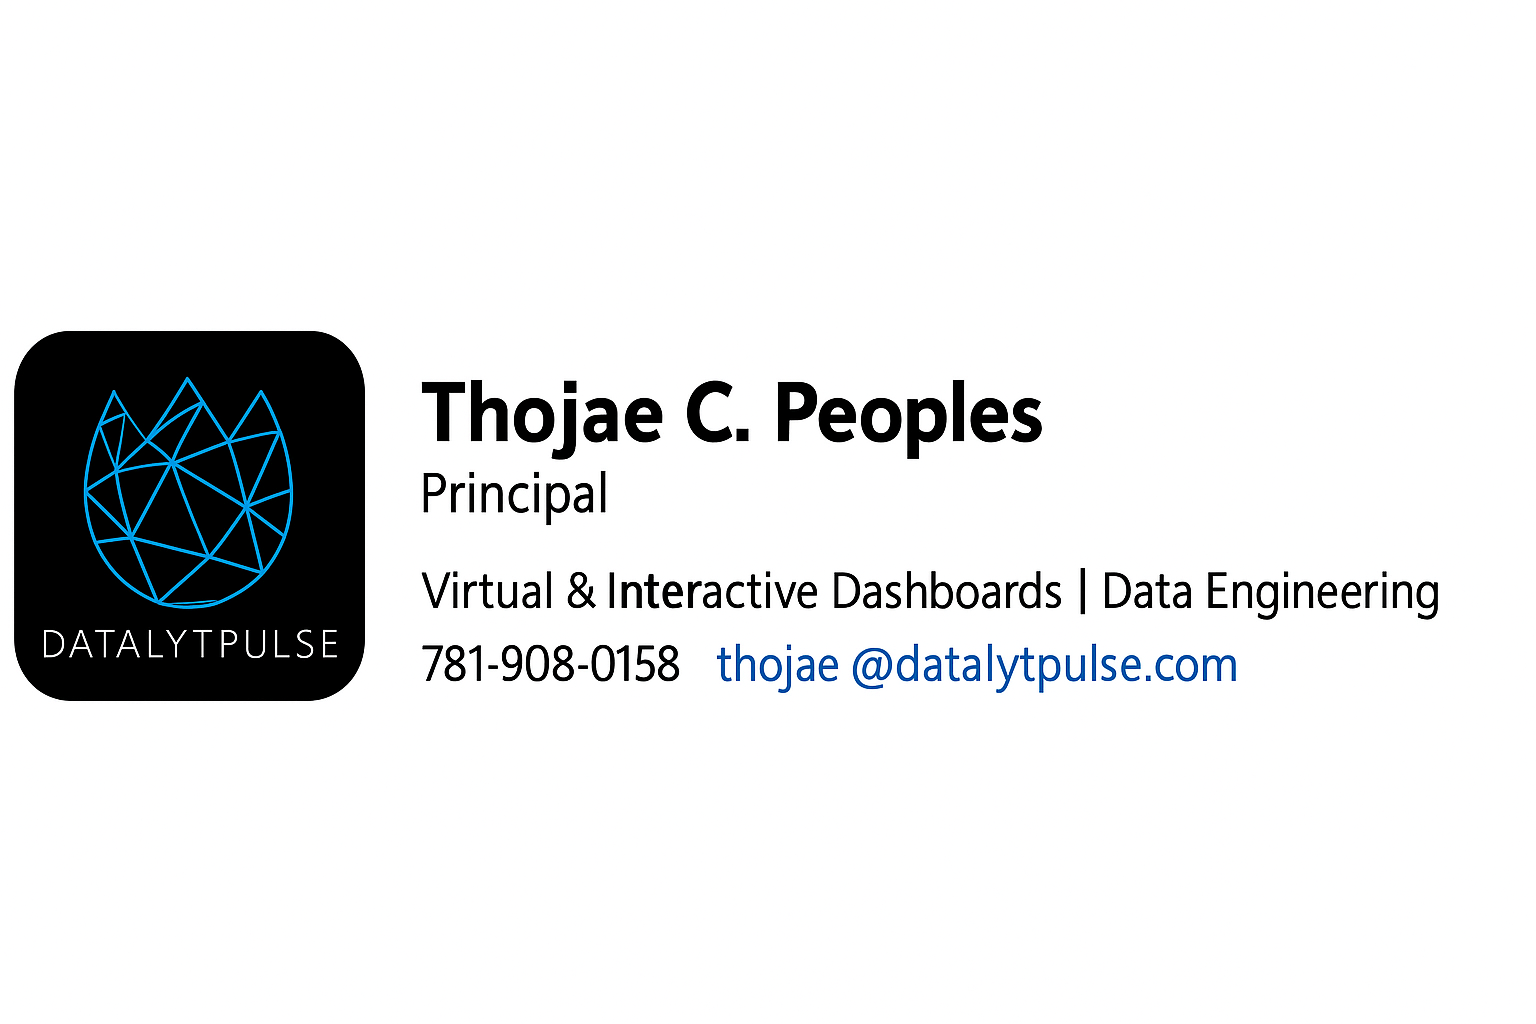

---

## Clean Up

In [ ]:
# Stop Spark session
spark.stop()
print("✅ Spark session stopped. Notebook complete!")

---

## Submission Checklist

| Item | Points | Done? |
|------|--------|-------|
| Part 1: Spark setup complete | 3 | ☐ |
| Part 2: Data partitioning demonstrated | 5 | ☐ |
| Part 3: Performance experiment with analysis | 5 | ☐ |
| Part 4: K-Means clustering on Netflix data | 5 | ☐ |
| Part 5: Diagram explaining distributed processing | 2 | ☐ |
| **Total** | **20** | |

---

## Resources

- [PySpark Documentation](https://spark.apache.org/docs/latest/api/python/)
- [How Netflix Uses Spark](https://netflixtechblog.com/spark-and-spark-streaming-at-netflix-21e9e5e3cd44)
- [K-Means Clustering Explained](https://scikit-learn.org/stable/modules/clustering.html#k-means)